In [79]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [2]:
# Create a comprehensive sample dataset for demonstration
np.random.seed(42)

n_samples = 1000

df = pd.DataFrame({
    'customer_id': range(1, n_samples + 1),
    'age': np.random.randint(18, 80, n_samples),
    'gender': np.random.choice(['Male', 'Female', 'Other'], n_samples, p=[0.48, 0.48, 0.04]),
    'income': np.random.normal(50000, 20000, n_samples),
    'credit_score': np.random.randint(300, 850, n_samples),
    'purchase_amount': np.random.exponential(100, n_samples),
    'num_purchases': np.random.poisson(5, n_samples),
    'satisfaction': np.random.choice(['Low', 'Medium', 'High'], n_samples, p=[0.2, 0.5, 0.3]),
    'region': np.random.choice(['North', 'South', 'East', 'West'], n_samples),
    'signup_date': pd.date_range('2020-01-01', periods=n_samples, freq='D')
})

# Introduce some missing values
df.loc[np.random.choice(df.index, 50, replace=False), 'income'] = np.nan
df.loc[np.random.choice(df.index, 30, replace=False), 'satisfaction'] = np.nan

# Introduce some outliers
df.loc[np.random.choice(df.index, 10, replace=False), 'purchase_amount'] = np.random.uniform(1000, 5000, 10)

print("Sample dataset created successfully!")
print(f"Dataset shape: {df.shape}")

Sample dataset created successfully!
Dataset shape: (1000, 10)


In [3]:
df

,customer_id,age,gender,income,credit_score,purchase_amount,num_purchases,satisfaction,region,signup_date
0,1,56,Male,25653.902883,453,41.767728,6,High,South,2020-01-01
1,2,69,Female,40359.064103,689,59.561911,5,Medium,South,2020-01-02
2,3,46,Male,22049.635343,559,244.452523,3,Medium,North,2020-01-03
3,4,32,Female,48095.098435,424,20.997244,7,High,North,2020-01-04
4,5,60,Female,57808.046878,653,0.503923,3,NaN,North,2020-01-05
...,...,...,...,...,...,...,...,...,...,...
995,996,18,Male,52422.938037,436,80.704053,2,Medium,North,2022-09-22
996,997,35,Female,66464.577567,666,71.944875,1,Medium,South,2022-09-23
997,998,49,Male,48388.962164,483,33.044064,2,Medium,North,2022-09-24
998,999,64,Female,39886.872801,586,172.725408,5,Medium,South,2022-09-25


In [4]:
df.head()

,customer_id,age,gender,income,credit_score,purchase_amount,num_purchases,satisfaction,region,signup_date
0,1,56,Male,25653.902883,453,41.767728,6,High,South,2020-01-01
1,2,69,Female,40359.064103,689,59.561911,5,Medium,South,2020-01-02
2,3,46,Male,22049.635343,559,244.452523,3,Medium,North,2020-01-03
3,4,32,Female,48095.098435,424,20.997244,7,High,North,2020-01-04
4,5,60,Female,57808.046878,653,0.503923,3,NaN,North,2020-01-05


In [5]:
df.tail()

,customer_id,age,gender,income,credit_score,purchase_amount,num_purchases,satisfaction,region,signup_date
995,996,18,Male,52422.938037,436,80.704053,2,Medium,North,2022-09-22
996,997,35,Female,66464.577567,666,71.944875,1,Medium,South,2022-09-23
997,998,49,Male,48388.962164,483,33.044064,2,Medium,North,2022-09-24
998,999,64,Female,39886.872801,586,172.725408,5,Medium,South,2022-09-25
999,1000,66,Female,38548.266723,771,139.775440,5,Medium,South,2022-09-26


In [6]:
df.shape

(1000, 10)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   customer_id      1000 non-null   int64         
 1   age              1000 non-null   int32         
 2   gender           1000 non-null   object        
 3   income           950 non-null    float64       
 4   credit_score     1000 non-null   int32         
 5   purchase_amount  1000 non-null   float64       
 6   num_purchases    1000 non-null   int32         
 7   satisfaction     970 non-null    object        
 8   region           1000 non-null   object        
 9   signup_date      1000 non-null   datetime64[ns]
dtypes: datetime64[ns](1), float64(2), int32(3), int64(1), object(3)
memory usage: 66.5+ KB


In [8]:
df.describe()

,customer_id,age,income,credit_score,purchase_amount,num_purchases,signup_date
count,1000.000000,1000.000000,950.000000,1000.000000,1000.000000,1000.000000,1000
mean,500.500000,49.857000,50314.479482,575.976000,119.505934,4.986000,2021-05-14 12:00:00
min,1.000000,18.000000,-17768.561653,300.000000,0.018655,0.000000,2020-01-01 00:00:00
25%,250.750000,35.000000,36284.610514,439.000000,25.546862,3.000000,2020-09-06 18:00:00
50%,500.500000,50.000000,50577.307185,573.500000,63.183635,5.000000,2021-05-14 12:00:00
75%,750.250000,66.000000,64331.212096,712.000000,136.835959,6.000000,2022-01-19 06:00:00
max,1000.000000,79.000000,115092.945863,849.000000,3698.723366,13.000000,2022-09-26 00:00:00
std,288.819436,18.114267,20429.473910,156.418017,282.147452,2.248747,NaN


In [9]:
print("Memory usage:")
print(df.memory_usage(deep=True))

Memory usage:
Index                132
customer_id         8000
age                 4000
gender             54066
income              8000
credit_score        4000
purchase_amount     8000
num_purchases       4000
satisfaction       53145
region             53505
signup_date         8000
dtype: int64


In [10]:
print(f"\nTotal memory usage: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")


Total memory usage: 0.20 MB


In [11]:
df.describe(include='O')

,gender,satisfaction,region
count,1000,970,1000
unique,3,3,4
top,Female,Medium,North
freq,513,488,256


In [12]:
print("\nSummary for all columns:")
df.describe(include='all')


Summary for all columns:


,customer_id,age,gender,income,credit_score,purchase_amount,num_purchases,satisfaction,region,signup_date
count,1000.000000,1000.000000,1000,950.000000,1000.000000,1000.000000,1000.000000,970,1000,1000
unique,NaN,NaN,3,NaN,NaN,NaN,NaN,3,4,NaN
top,NaN,NaN,Female,NaN,NaN,NaN,NaN,Medium,North,NaN
freq,NaN,NaN,513,NaN,NaN,NaN,NaN,488,256,NaN
mean,500.500000,49.857000,NaN,50314.479482,575.976000,119.505934,4.986000,NaN,NaN,2021-05-14 12:00:00
min,1.000000,18.000000,NaN,-17768.561653,300.000000,0.018655,0.000000,NaN,NaN,2020-01-01 00:00:00
25%,250.750000,35.000000,NaN,36284.610514,439.000000,25.546862,3.000000,NaN,NaN,2020-09-06 18:00:00
50%,500.500000,50.000000,NaN,50577.307185,573.500000,63.183635,5.000000,NaN,NaN,2021-05-14 12:00:00
75%,750.250000,66.000000,NaN,64331.212096,712.000000,136.835959,6.000000,NaN,NaN,2022-01-19 06:00:00
max,1000.000000,79.000000,NaN,115092.945863,849.000000,3698.723366,13.000000,NaN,NaN,2022-09-26 00:00:00


In [13]:
categorical_df = df.select_dtypes(include='O')
categorical_df

,gender,satisfaction,region
0,Male,High,South
1,Female,Medium,South
2,Male,Medium,North
3,Female,High,North
4,Female,NaN,North
...,...,...,...
995,Male,Medium,North
996,Female,Medium,South
997,Male,Medium,North
998,Female,Medium,South


In [64]:
numerical_df = df.select_dtypes(exclude='O')
numerical_df

,customer_id,age,income,credit_score,purchase_amount,num_purchases,signup_date,imputed_income
0,1,56,25653.902883,453,41.767728,6,2020-01-01,25653.902883
1,2,69,40359.064103,689,59.561911,5,2020-01-02,40359.064103
2,3,46,22049.635343,559,244.452523,3,2020-01-03,22049.635343
3,4,32,48095.098435,424,20.997244,7,2020-01-04,48095.098435
4,5,60,57808.046878,653,0.503923,3,2020-01-05,57808.046878
...,...,...,...,...,...,...,...,...
995,996,18,52422.938037,436,80.704053,2,2022-09-22,52422.938037
996,997,35,66464.577567,666,71.944875,1,2022-09-23,66464.577567
997,998,49,48388.962164,483,33.044064,2,2022-09-24,48388.962164
998,999,64,39886.872801,586,172.725408,5,2022-09-25,39886.872801


In [15]:
for col in df.columns:
    print(col)
    print(df[col].nunique())
    print("*"*10)

customer_id
1000
**********
age
62
**********
gender
3
**********
income
950
**********
credit_score
459
**********
purchase_amount
1000
**********
num_purchases
14
**********
satisfaction
3
**********
region
4
**********
signup_date
1000
**********


In [16]:
# Cardinality analysis
def analyze_cardinality(df):
    """Analyze cardinality of each column"""
    cardinality = pd.DataFrame({
        'column': df.columns,
        'unique_values': [df[col].nunique() for col in df.columns],
        'total_values': [df[col].count() for col in df.columns]
    })
    cardinality['cardinality_ratio'] = cardinality['unique_values'] / cardinality['total_values']
    cardinality['type'] = cardinality['cardinality_ratio'].apply(
        lambda x: 'High' if x > 0.5 else ('Medium' if x > 0.05 else 'Low')
    )
    return cardinality.sort_values('cardinality_ratio', ascending=False)

print("\nCardinality Analysis:")
print(analyze_cardinality(df))


Cardinality Analysis:
            column  unique_values  total_values  cardinality_ratio    type
0      customer_id           1000          1000           1.000000    High
3           income            950           950           1.000000    High
9      signup_date           1000          1000           1.000000    High
5  purchase_amount           1000          1000           1.000000    High
4     credit_score            459          1000           0.459000  Medium
1              age             62          1000           0.062000  Medium
6    num_purchases             14          1000           0.014000     Low
8           region              4          1000           0.004000     Low
7     satisfaction              3           970           0.003093     Low
2           gender              3          1000           0.003000     Low


In [17]:
# Count missing values
print("Missing values count:")
missing_count = df.isnull().sum()
missing_count
print(missing_count[missing_count > 0])

Missing values count:
income          50
satisfaction    30
dtype: int64


Mean/Median/Mode Imputation: Replace missing values with the mean (numerical), median (skewed data), or mode (categorical) of the feature. Simple but can distort distribution.

In [22]:
df[['income']]

,income
0,25653.902883
1,40359.064103
2,22049.635343
3,48095.098435
4,57808.046878
...,...
995,52422.938037
996,66464.577567
997,48388.962164
998,39886.872801


In [23]:
from sklearn.impute import SimpleImputer
import numpy as np

# Sample data with missing values
X = np.array([[1, 2, np.nan],
              [3, np.nan, 6],
              [np.nan, 8, 9]])

# # Mean imputation for numerical data
imputer_mean = SimpleImputer(strategy='mean')
imputed_income = imputer_mean.fit_transform(df[['income']])
df['imputed_income'] = imputed_income

In [24]:
df.isnull().sum()

customer_id         0
age                 0
gender              0
income             50
credit_score        0
purchase_amount     0
num_purchases       0
satisfaction       30
region              0
signup_date         0
imputed_income      0
dtype: int64

In [ ]:

imputer_mode = SimpleImputer(strategy='most_frequent')
imputed_satisfaction = imputer_mode.fit_transform(df[['satisfaction']])


In [ ]:


# # Median imputation
# imputer_median = SimpleImputer(strategy='median')
# X_median = imputer_median.fit_transform(X)

# # Most frequent for categorical data


# # Constant value imputation
# imputer_constant = SimpleImputer(strategy='constant', fill_value=0)
# X_constant = imputer_constant.fit_transform(X)

ValueError: 2

In [42]:
from sklearn.impute import KNNImputer

X = np.array([[1, 2, np.nan],
              [3, 4, 3],
              [np.nan, 6, 5],
              [8, 8, 7]])

# Using 2 nearest neighbors
imputer_knn = KNNImputer(n_neighbors=2, weights='uniform')
X_knn = imputer_knn.fit_transform(X)

# Using distance-weighted neighbors
imputer_knn_dist = KNNImputer(n_neighbors=3, weights='distance')
X_knn_dist = imputer_knn_dist.fit_transform(X)

In [44]:
X_knn

array([[1. , 2. , 4. ],
       [3. , 4. , 3. ],
       [5.5, 6. , 5. ],
       [8. , 8. , 7. ]])

In [45]:
X_knn_dist

array([[1.        , 2.        , 4.23265511],
       [3.        , 4.        , 3.        ],
       [4.6       , 6.        , 5.        ],
       [8.        , 8.        , 7.        ]])

In [52]:
df['satisfaction'].isnull().sum()/df.shape[0]*100

np.float64(3.0)

In [49]:
df['income'].isnull().sum()/df.shape[0]*100

np.float64(5.0)

In [54]:
for i in df.columns:
    print(i, df[i].isnull().sum()/df.shape[0]*100,'%')


customer_id 0.0 %
age 0.0 %
gender 0.0 %
income 5.0 %
credit_score 0.0 %
purchase_amount 0.0 %
num_purchases 0.0 %
satisfaction 3.0 %
region 0.0 %
signup_date 0.0 %
imputed_income 0.0 %


In [58]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.drop_duplicates()

In [61]:
df['purchase_amount'].astype('int')

0       41
1       59
2      244
3       20
4        0
      ... 
995     80
996     71
997     33
998    172
999    139
Name: purchase_amount, Length: 1000, dtype: int64

In [65]:
numerical_df = numerical_df.drop(columns=['signup_date','customer_id'], axis=1)
numerical_df

,age,income,credit_score,purchase_amount,num_purchases,imputed_income
0,56,25653.902883,453,41.767728,6,25653.902883
1,69,40359.064103,689,59.561911,5,40359.064103
2,46,22049.635343,559,244.452523,3,22049.635343
3,32,48095.098435,424,20.997244,7,48095.098435
4,60,57808.046878,653,0.503923,3,57808.046878
...,...,...,...,...,...,...
995,18,52422.938037,436,80.704053,2,52422.938037
996,35,66464.577567,666,71.944875,1,66464.577567
997,49,48388.962164,483,33.044064,2,48388.962164
998,64,39886.872801,586,172.725408,5,39886.872801


In [71]:
df[df['income'] < 0]

,customer_id,age,gender,income,credit_score,purchase_amount,num_purchases,satisfaction,region,signup_date,imputed_income
147,148,76,Female,-17768.561653,735,123.827018,3,Medium,North,2020-05-27,-17768.561653
375,376,26,Male,-6124.342190,789,163.745636,4,High,East,2021-01-10,-6124.342190
470,471,54,Male,-5191.947985,426,26.467065,5,Medium,East,2021-04-15,-5191.947985
600,601,79,Male,-36.057228,685,83.677000,4,Medium,East,2021-08-23,-36.057228
604,605,70,Male,-348.662048,635,12.381750,9,High,South,2021-08-27,-348.662048
826,827,64,Female,-469.749404,670,217.080269,4,Low,South,2022-04-06,-469.749404


age


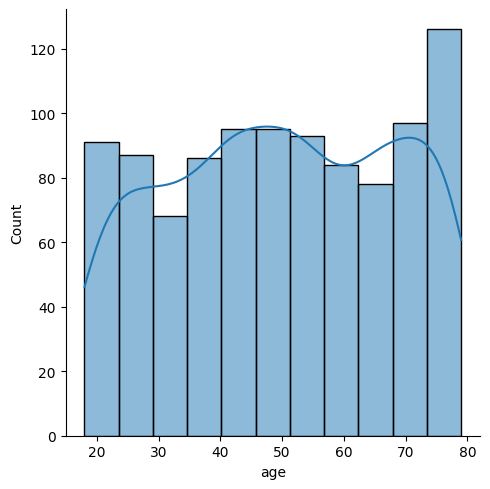

income


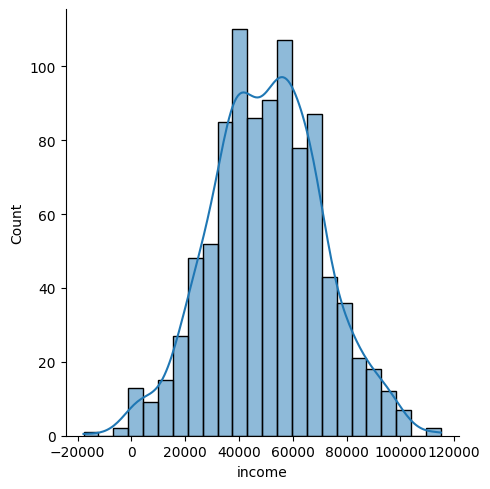

credit_score


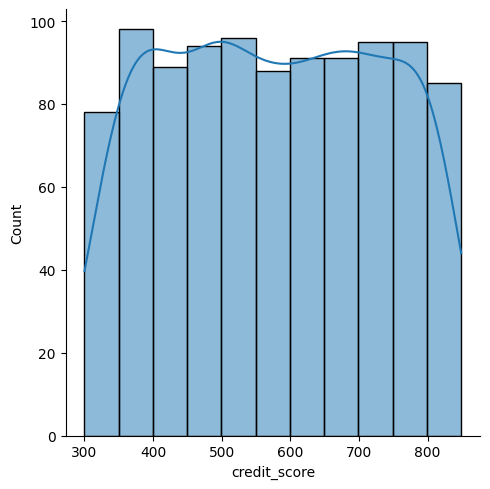

purchase_amount


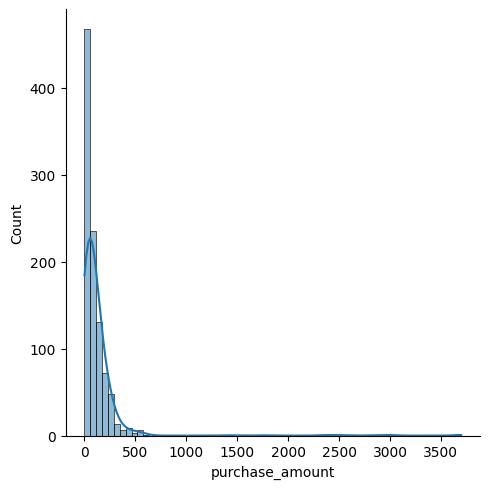

num_purchases


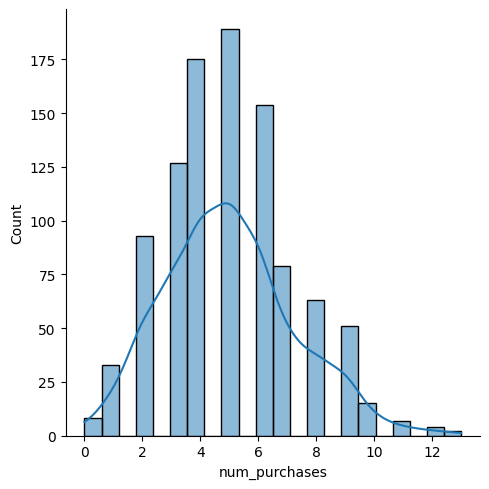

imputed_income


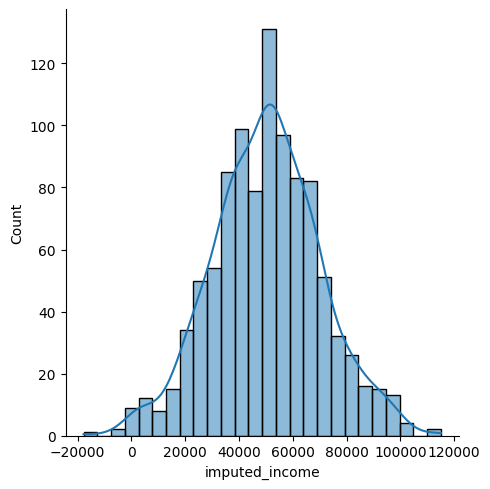

In [68]:
for num_col in numerical_df.columns:
    print(num_col)
    sns.displot(numerical_df[num_col], kde=True)
    plt.show()


Frequency Distribution of gender
gender
Female    513
Male      447
Other      40
Name: count, dtype: int64

Percentage Distribution:
gender
Female    51.3
Male      44.7
Other      4.0
Name: proportion, dtype: float64

Mode: Female


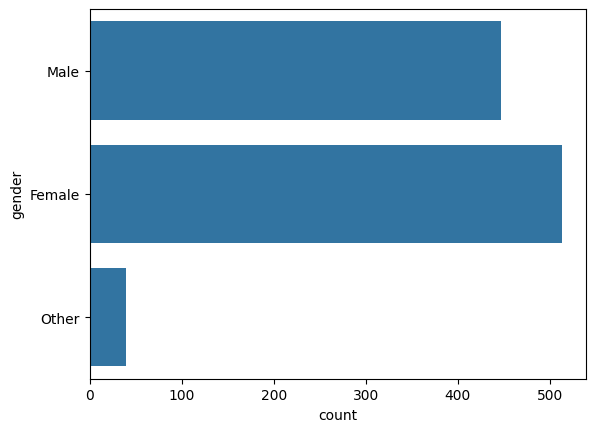


Frequency Distribution of satisfaction
satisfaction
Medium    488
High      281
Low       201
Name: count, dtype: int64

Percentage Distribution:
satisfaction
Medium    50.309278
High      28.969072
Low       20.721649
Name: proportion, dtype: float64

Mode: Medium


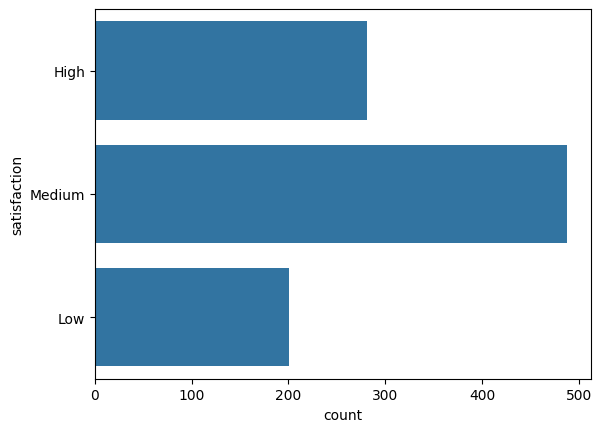


Frequency Distribution of region
region
North    256
East     251
South    249
West     244
Name: count, dtype: int64

Percentage Distribution:
region
North    25.6
East     25.1
South    24.9
West     24.4
Name: proportion, dtype: float64

Mode: North


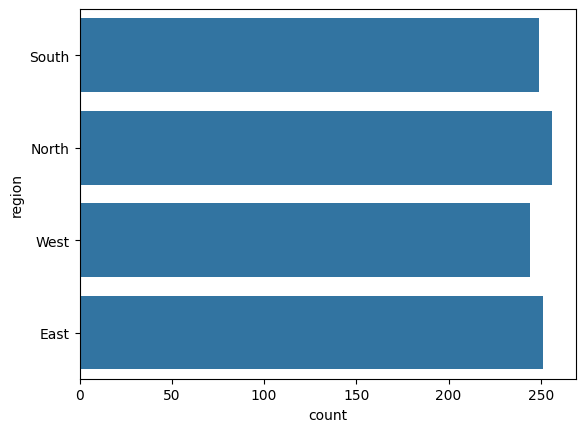

In [76]:
for col in ['gender', 'satisfaction', 'region']:
    print(f"\n{'='*50}")
    print(f"Frequency Distribution of {col}")
    print(f"{'='*50}")
    
    # Value counts
    print(df[col].value_counts())
    
    # Percentage distribution
    print("\nPercentage Distribution:")
    print(df[col].value_counts(normalize=True) * 100)
    
    # Mode
    print(f"\nMode: {df[col].mode().values[0]}")

    sns.countplot(categorical_df[col])
    plt.show()

Correlation Matrix:
                      age    income  credit_score  purchase_amount  \
age              1.000000 -0.046049      0.048381        -0.002521   
income          -0.046049  1.000000     -0.003856        -0.028838   
credit_score     0.048381 -0.003856      1.000000         0.024459   
purchase_amount -0.002521 -0.028838      0.024459         1.000000   
num_purchases    0.023935  0.024025     -0.002050         0.008923   
imputed_income  -0.045242  1.000000     -0.003748        -0.028708   

                 num_purchases  imputed_income  
age                   0.023935       -0.045242  
income                0.024025        1.000000  
credit_score         -0.002050       -0.003748  
purchase_amount       0.008923       -0.028708  
num_purchases         1.000000        0.023349  
imputed_income        0.023349        1.000000  


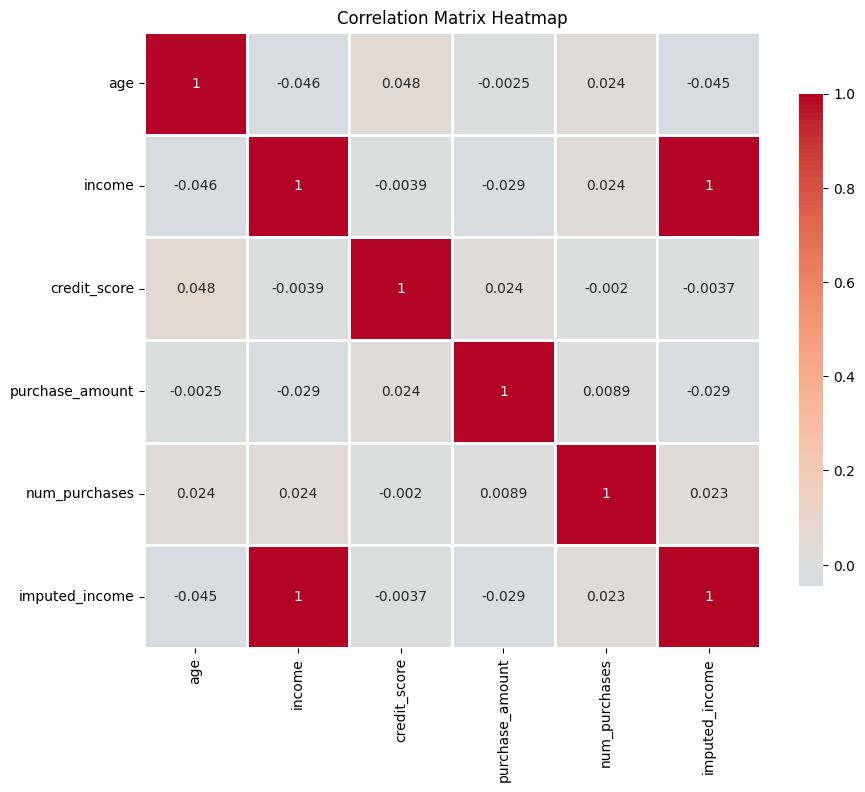

In [77]:
correlation_matrix = df[numerical_df.columns].corr()

print("Correlation Matrix:")
print(correlation_matrix)

# Visualize correlation matrix
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0,
            square=True, linewidths=1, cbar_kws={"shrink": 0.8})
plt.title('Correlation Matrix Heatmap')
plt.show()

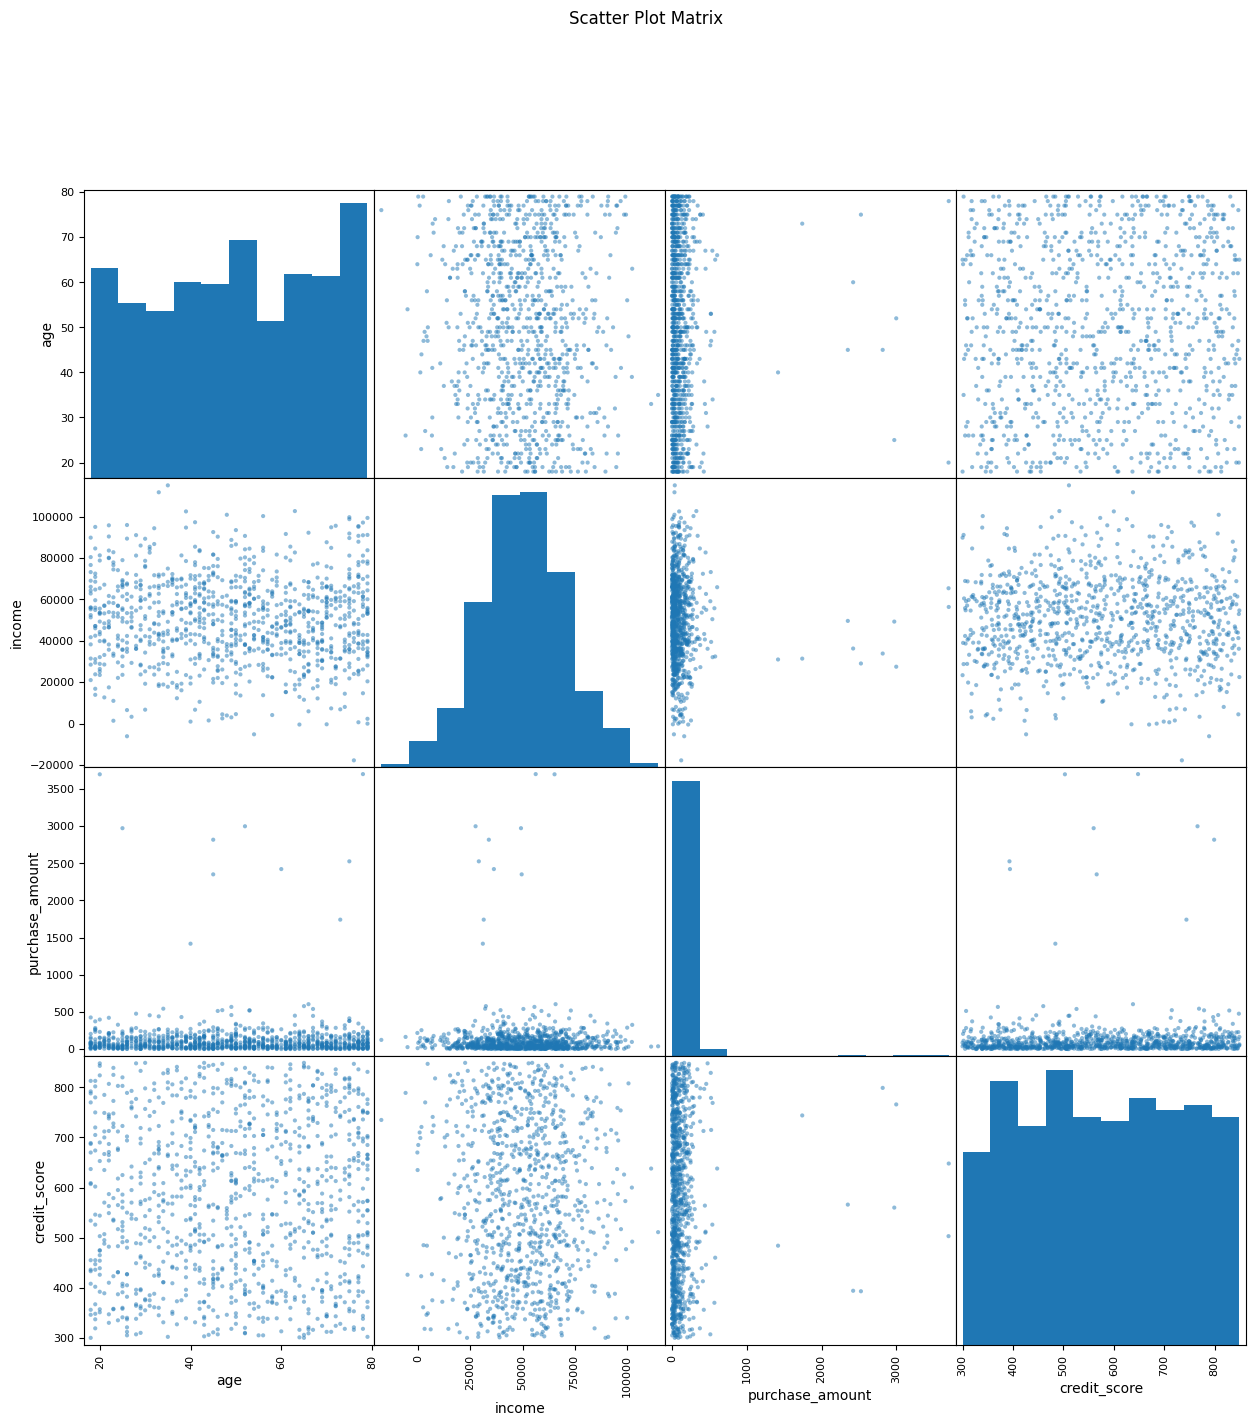

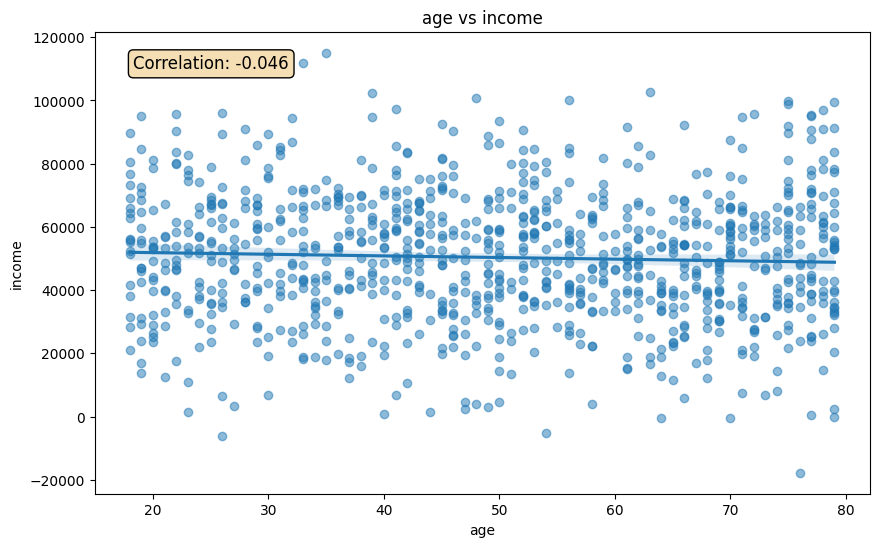

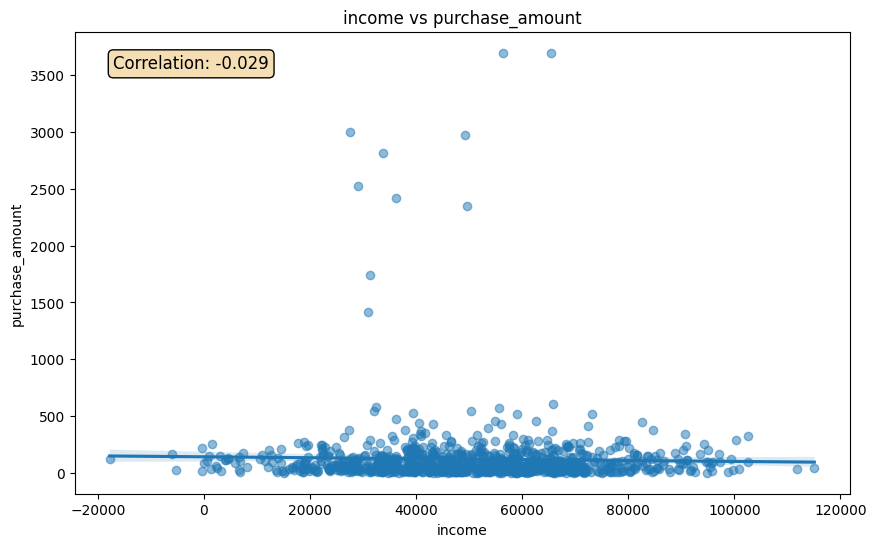

In [78]:
# Scatter plots
def plot_scatter_matrix(df, columns):
    """Create scatter plot matrix"""
    pd.plotting.scatter_matrix(df[columns], figsize=(15, 15), 
                              alpha=0.5, diagonal='hist')
    plt.suptitle('Scatter Plot Matrix', y=1.0)
    plt.show()

plot_scatter_matrix(df, ['age', 'income', 'purchase_amount', 'credit_score'])

# Individual scatter plots with regression line
def plot_scatter_with_regression(df, x_col, y_col):
    """Scatter plot with regression line"""
    plt.figure(figsize=(10, 6))
    sns.regplot(data=df, x=x_col, y=y_col, scatter_kws={'alpha':0.5})
    plt.title(f'{x_col} vs {y_col}')
    plt.xlabel(x_col)
    plt.ylabel(y_col)
    
    # Calculate and display correlation
    corr = df[[x_col, y_col]].corr().iloc[0, 1]
    plt.text(0.05, 0.95, f'Correlation: {corr:.3f}', 
             transform=plt.gca().transAxes, fontsize=12,
             verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat'))
    plt.show()

plot_scatter_with_regression(df, 'age', 'income')
plot_scatter_with_regression(df, 'income', 'purchase_amount')

In [ ]:
# Gender vs purchase_amount
# drop specific rows from the dataframe



In [81]:
titanic_df = sns.load_dataset(name='titanic')
titanic_df

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


In [83]:
titanic_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [82]:
titanic_df[['fare','age']]

,fare,age
0,7.2500,22.0
1,71.2833,38.0
2,7.9250,26.0
3,53.1000,35.0
4,8.0500,35.0
...,...,...
886,13.0000,27.0
887,30.0000,19.0
888,23.4500,NaN
889,30.0000,26.0


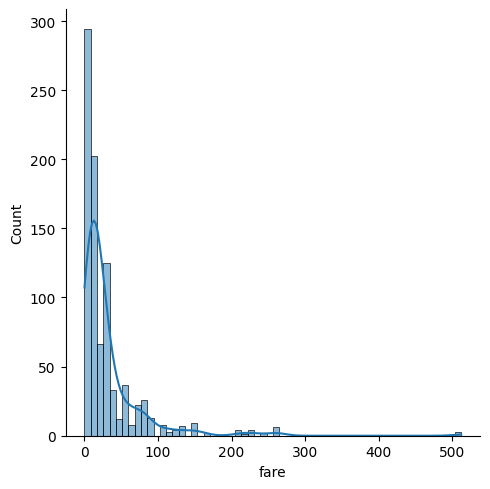

In [86]:
sns.displot(titanic_df['fare'], kde=True)

In [ ]:
!pip install scikit-learn

In [87]:
from sklearn.preprocessing import StandardScaler


std_scaler = StandardScaler()
scaled_fare = std_scaler.fit_transform(titanic_df[['fare']])


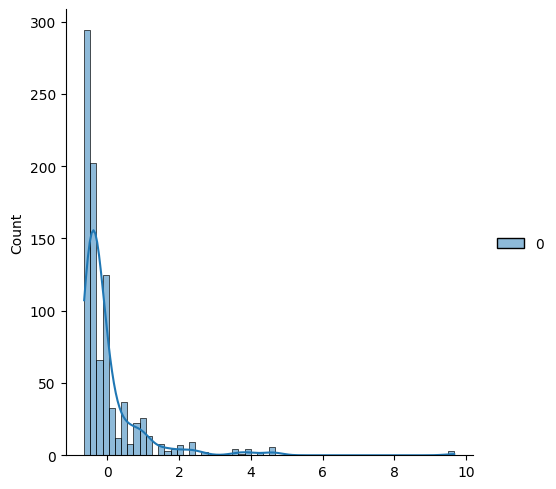

In [88]:
sns.displot(scaled_fare, kde=True)


In [89]:
std_scaler = StandardScaler()
scaled_age = std_scaler.fit_transform(titanic_df[['age']])

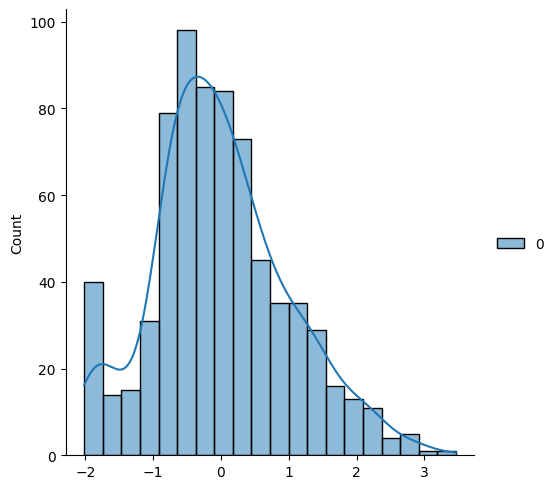

In [90]:
sns.displot(scaled_age, kde=True)


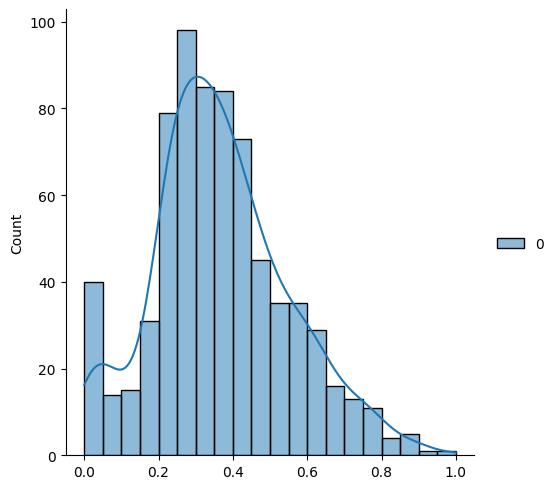

In [91]:
from sklearn.preprocessing import MinMaxScaler


minmax_sclar = MinMaxScaler()
scaled_age_mx_scaler = minmax_sclar.fit_transform(titanic_df[['age']])

sns.displot(scaled_age_mx_scaler,kde=True)

In [97]:
from sklearn.preprocessing import PowerTransformer

salary = [17654762,3667345,377654726,7652312,87645346,876451365]

salary = np.array(salary, ndmin=2)

transformer = PowerTransformer()
age_transformer = transformer.fit_transform(salary)

age_transformer


array([[0., 0., 0., 0., 0., 0.]])

In [ ]:
# Categorical Encoding


